In [9]:
import time
import heapq
from collections import deque
import matplotlib.pyplot as plt

In [10]:
JUG_A = 4
JUG_B = 3
TARGET = 2

initial_state = (0, 0)

def is_goal(state):
    return state[0] == TARGET or state[1] == TARGET

In [11]:
def get_successors(state):

    a, b = state

    successors = []

    # Fill Jug A
    successors.append((JUG_A, b))

    # Fill Jug B
    successors.append((a, JUG_B))

    # Empty Jug A
    successors.append((0, b))

    # Empty Jug B
    successors.append((a, 0))

    # Pour Jug A into Jug B
    pour = min(a, JUG_B - b)

    successors.append((a - pour, b + pour))

    # Pour Jug B into Jug A
    pour = min(b, JUG_A - a)

    successors.append((a + pour, b - pour))

    # Remove duplicate states and unchanged states
    return list(set(
        s for s in successors if s != state
    ))

In [12]:
def dfs(start):

    stack = [(start, [start])]

    visited = set()

    nodes_explored = 0

    while stack:

        state, path = stack.pop()

        if state in visited:
            continue

        visited.add(state)
        nodes_explored += 1

        if is_goal(state):
            return path, nodes_explored

        for neighbor in get_successors(state):

            if neighbor not in visited:

                stack.append(
                    (neighbor, path + [neighbor])
                )

    return None, nodes_explored

In [13]:
def bfs(start):

    queue = deque([(start, [start])])

    visited = {start}

    nodes_explored = 0

    while queue:

        state, path = queue.popleft()

        nodes_explored += 1

        if is_goal(state):
            return path, nodes_explored

        for neighbor in get_successors(state):

            if neighbor not in visited:

                visited.add(neighbor)

                queue.append(
                    (neighbor, path + [neighbor])
                )

    return None, nodes_explored

In [14]:
def heuristic(state):

    a, b = state

    return min(
        abs(a - TARGET) + b,
        abs(b - TARGET) + a
    )


def hill_climbing(start):

    current = start

    path = [current]

    visited = {current}

    nodes_explored = 1

    while not is_goal(current):

        neighbors = get_successors(current)

        # Select the best unvisited neighbor
        neighbors = [
            n for n in neighbors if n not in visited
        ]

        if not neighbors:
            return None, nodes_explored

        best_neighbor = min(
            neighbors,
            key=heuristic
        )

        # Stop if no improvement is possible
        if heuristic(best_neighbor) >= heuristic(current):
            return None, nodes_explored

        current = best_neighbor

        visited.add(current)

        path.append(current)

        nodes_explored += 1

    return path, nodes_explored

In [15]:
def heuristic(state):

    a, b = state

    return min(
        abs(a - TARGET) + b,
        abs(b - TARGET) + a
    )


def hill_climbing(start):

    current = start

    path = [current]

    visited = {current}

    nodes_explored = 1

    while not is_goal(current):

        neighbors = get_successors(current)

        # Select the best unvisited neighbor
        neighbors = [
            n for n in neighbors if n not in visited
        ]

        if not neighbors:
            return None, nodes_explored

        best_neighbor = min(
            neighbors,
            key=heuristic
        )

        # Stop if no improvement is possible
        if heuristic(best_neighbor) >= heuristic(current):
            return None, nodes_explored

        current = best_neighbor

        visited.add(current)

        path.append(current)

        nodes_explored += 1

    return path, nodes_explored

In [16]:
def best_first_search(start):

    priority_queue = []

    heapq.heappush(
        priority_queue,
        (heuristic(start), start, [start])
    )

    visited = set()

    nodes_explored = 0

    while priority_queue:

        h, state, path = heapq.heappop(priority_queue)

        if state in visited:
            continue

        visited.add(state)

        nodes_explored += 1

        if is_goal(state):
            return path, nodes_explored

        for neighbor in get_successors(state):

            if neighbor not in visited:

                heapq.heappush(
                    priority_queue,
                    (
                        heuristic(neighbor),
                        neighbor,
                        path + [neighbor]
                    )
                )

    return None, nodes_explored

In [17]:
algorithms = {
    "DFS": dfs,
    "BFS": bfs,
    "Hill Climbing": hill_climbing,
    "Best First Search": best_first_search
}

results = {}

for name, algorithm in algorithms.items():

    start_time = time.perf_counter()

    path, explored = algorithm(initial_state)

    end_time = time.perf_counter()

    execution_time = end_time - start_time

    results[name] = {
        "path": path,
        "explored": explored,
        "time": execution_time
    }

    print("\nAlgorithm:", name)

    if path:

        print("Solution Found!")

        for step, state in enumerate(path):

            print(
                f"Step {step}: "
                f"Jug A = {state[0]}, "
                f"Jug B = {state[1]}"
            )

        print("Total Moves:", len(path) - 1)

    else:

        print("No Solution Found!")

    print("Nodes Explored:", explored)

    print("Execution Time:", execution_time)


Algorithm: DFS
Solution Found!
Step 0: Jug A = 0, Jug B = 0
Step 1: Jug A = 0, Jug B = 3
Step 2: Jug A = 4, Jug B = 3
Step 3: Jug A = 4, Jug B = 0
Step 4: Jug A = 1, Jug B = 3
Step 5: Jug A = 1, Jug B = 0
Step 6: Jug A = 0, Jug B = 1
Step 7: Jug A = 4, Jug B = 1
Step 8: Jug A = 2, Jug B = 3
Total Moves: 8
Nodes Explored: 9
Execution Time: 5.806299986943486e-05

Algorithm: BFS
Solution Found!
Step 0: Jug A = 0, Jug B = 0
Step 1: Jug A = 0, Jug B = 3
Step 2: Jug A = 3, Jug B = 0
Step 3: Jug A = 3, Jug B = 3
Step 4: Jug A = 4, Jug B = 2
Total Moves: 4
Nodes Explored: 10
Execution Time: 4.8103000153787434e-05

Algorithm: Hill Climbing
No Solution Found!
Nodes Explored: 2
Execution Time: 2.3517000045103487e-05

Algorithm: Best First Search
Solution Found!
Step 0: Jug A = 0, Jug B = 0
Step 1: Jug A = 0, Jug B = 3
Step 2: Jug A = 3, Jug B = 0
Step 3: Jug A = 4, Jug B = 0
Step 4: Jug A = 1, Jug B = 3
Step 5: Jug A = 1, Jug B = 0
Step 6: Jug A = 0, Jug B = 1
Step 7: Jug A = 4, Jug B = 1
Step 8

In [18]:
print("\n========== ALGORITHM COMPARISON ==========")

print(
    f"{'Algorithm':<22}"
    f"{'Moves':<12}"
    f"{'Nodes':<12}"
    f"{'Time (sec)':<15}"
)

for name, result in results.items():

    moves = (
        len(result["path"]) - 1
        if result["path"] else "Failed"
    )

    print(
        f"{name:<22}"
        f"{str(moves):<12}"
        f"{result['explored']:<12}"
        f"{result['time']:<15.8f}"
    )


========== ALGORITHM COMPARISON ==========
Algorithm             Moves       Nodes       Time (sec)     
DFS                   8           9           0.00005806     
BFS                   4           10          0.00004810     
Hill Climbing         Failed      2           0.00002352     
Best First Search     8           9           0.00004908     


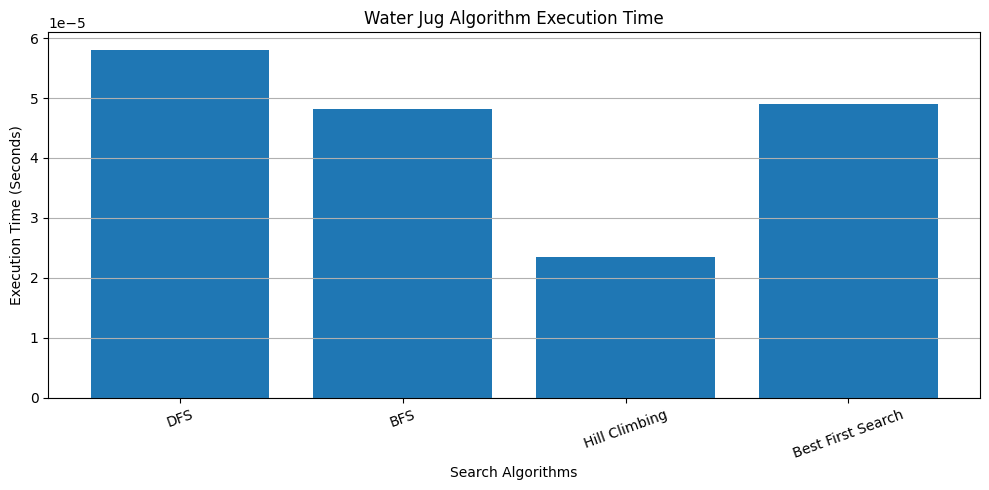

In [19]:
names = list(results.keys())

times = [
    results[name]["time"]
    for name in names
]

plt.figure(figsize=(10, 5))

plt.bar(names, times)

plt.title("Water Jug Algorithm Execution Time")

plt.xlabel("Search Algorithms")

plt.ylabel("Execution Time (Seconds)")

plt.xticks(rotation=20)

plt.grid(axis="y")

plt.tight_layout()

plt.show()